# Task 4, Task 5 & Task 6 — Frequent Pattern Mining, Association Rule Mining & Algorithm Performance Comparison

Notebook ini mencakup eksperimen lengkap pada **Author-Based Transactional Database** (2015–2025):
- **Task 4**: Implementasi & eksperimen **Apriori** dan **FP-Growth** pada 4 nilai `min_support`: `0.1%`, `0.5%`, `1%`, dan `2%`.
- **Task 5**: Pembangkitan **Association Rules** (`min_confidence = 50%`), perhitungan `support`, `confidence`, `lift`, Top 10 rules berdasarkan `lift`, serta analisis hubungan *support* vs *lift*.
- **Task 6**: Perbandingan performa **Apriori** vs **FP-Growth** (jumlah frequent itemsets, jumlah association rules, waktu eksekusi, peak memory, dan kesetaraan hasil).


In [1]:
import os
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.plotting import PALETTE, apply_publication_style, clean_axes, save_figure

apply_publication_style(base_font_size=11)
os.makedirs("../outputs/figures", exist_ok=True)

size_df = pd.read_csv("../tables/task4_itemset_counts_by_size.csv")
top10_is = pd.read_csv("../tables/task4_top10_itemsets_per_minsup.csv")
is_01 = pd.read_csv("../tables/task4_frequent_itemsets_01pct.csv")
rules_01 = pd.read_csv("../tables/task5_association_rules_01pct.csv")
top10_rules = pd.read_csv("../tables/task5_top10_rules_by_lift.csv")
comp_df = pd.read_csv("../tables/task6_algorithm_comparison.csv")


## 1. Task 4 — Frequent Pattern Mining (Apriori & FP-Growth)


In [2]:
print("=== Jumlah Frequent Itemsets Berdasarkan Ukuran (1-, 2-, 3-itemsets) ===")
display(size_df)

for ms in [0.001, 0.005, 0.01, 0.02]:
    print(f"\n=== Top 10 Frequent Itemsets (min_support = {ms*100:.1f}%) ===")
    display(top10_is[top10_is["min_support"] == ms])


=== Jumlah Frequent Itemsets Berdasarkan Ukuran (1-, 2-, 3-itemsets) ===


,min_support,min_support_pct,n_1_itemsets,n_2_itemsets,n_3_itemsets,n_4plus_itemsets,total_itemsets,total_rules_conf50
0,0.001,0.1%,534,333,237,93,1197,730
1,0.005,0.5%,63,11,1,0,75,6
2,0.010,1.0%,24,1,0,0,25,1
3,0.020,2.0%,4,0,0,0,4,0



=== Top 10 Frequent Itemsets (min_support = 0.1%) ===


,min_support,itemset,length,support,support_pct,tx_count
0,0.001,NeurIPS,1,0.030767,3.0767,56073
1,0.001,AAAI,1,0.024474,2.4474,44604
2,0.001,ICASSP,1,0.022550,2.2550,41097
3,0.001,EMBC,1,0.021574,2.1574,39318
4,0.001,IGARSS,1,0.019330,1.9330,35229
5,0.001,CVPR,1,0.019188,1.9188,34970
6,0.001,ICML,1,0.017228,1.7228,31397
7,0.001,IROS,1,0.017119,1.7119,31200
8,0.001,IJCNN,1,0.016353,1.6353,29803
9,0.001,ICLR,1,0.015776,1.5776,28751



=== Top 10 Frequent Itemsets (min_support = 0.5%) ===


,min_support,itemset,length,support,support_pct,tx_count
10,0.005,NeurIPS,1,0.030767,3.0767,56073
11,0.005,AAAI,1,0.024474,2.4474,44604
12,0.005,ICASSP,1,0.022550,2.2550,41097
13,0.005,EMBC,1,0.021574,2.1574,39318
14,0.005,IGARSS,1,0.019330,1.9330,35229
15,0.005,CVPR,1,0.019188,1.9188,34970
16,0.005,ICML,1,0.017228,1.7228,31397
17,0.005,IROS,1,0.017119,1.7119,31200
18,0.005,IJCNN,1,0.016353,1.6353,29803
19,0.005,ICLR,1,0.015776,1.5776,28751



=== Top 10 Frequent Itemsets (min_support = 1.0%) ===


,min_support,itemset,length,support,support_pct,tx_count
20,0.01,NeurIPS,1,0.030767,3.0767,56073
21,0.01,AAAI,1,0.024474,2.4474,44604
22,0.01,ICASSP,1,0.022550,2.2550,41097
23,0.01,EMBC,1,0.021574,2.1574,39318
24,0.01,IGARSS,1,0.019330,1.9330,35229
25,0.01,CVPR,1,0.019188,1.9188,34970
26,0.01,ICML,1,0.017228,1.7228,31397
27,0.01,IROS,1,0.017119,1.7119,31200
28,0.01,IJCNN,1,0.016353,1.6353,29803
29,0.01,ICLR,1,0.015776,1.5776,28751



=== Top 10 Frequent Itemsets (min_support = 2.0%) ===


,min_support,itemset,length,support,support_pct,tx_count
30,0.02,NeurIPS,1,0.030767,3.0767,56073
31,0.02,AAAI,1,0.024474,2.4474,44604
32,0.02,ICASSP,1,0.022550,2.2550,41097
33,0.02,EMBC,1,0.021574,2.1574,39318


In [3]:
print("=== Top 15 Kombinasi Conference (2-itemsets) pada min_support = 0.1% ===")
display(is_01[is_01["length"] == 2].head(15))

print("\n=== Top 15 Kombinasi Conference (3-itemsets) pada min_support = 0.1% ===")
display(is_01[is_01["length"] == 3].head(15))


=== Top 15 Kombinasi Conference (2-itemsets) pada min_support = 0.1% ===


,min_support,itemset,length,support,support_pct,tx_count
24,0.001,"ICML, NeurIPS",2,0.010008,1.0008,18239
26,0.001,"ICLR, NeurIPS",2,0.009263,0.9263,16882
31,0.001,"AAAI, NeurIPS",2,0.008534,0.8534,15554
40,0.001,"CVPR, NeurIPS",2,0.007685,0.7685,14006
43,0.001,"CVPR, ICCV",2,0.007456,0.7456,13588
50,0.001,"ICLR, ICML",2,0.006741,0.6741,12285
51,0.001,"ICRA, IROS",2,0.006507,0.6507,11859
58,0.001,"AAAI, IJCAI",2,0.006041,0.6041,11010
60,0.001,"AAAI, CVPR",2,0.005958,0.5958,10858
63,0.001,"ICCV, NeurIPS",2,0.005727,0.5727,10437



=== Top 15 Kombinasi Conference (3-itemsets) pada min_support = 0.1% ===


,min_support,itemset,length,support,support_pct,tx_count
68,0.001,"ICLR, ICML, NeurIPS",3,0.005445,0.5445,9924
98,0.001,"CVPR, ICCV, NeurIPS",3,0.004281,0.4281,7802
106,0.001,"AAAI, ICML, NeurIPS",3,0.004091,0.4091,7456
115,0.001,"AAAI, ICLR, NeurIPS",3,0.003844,0.3844,7005
119,0.001,"AAAI, CVPR, NeurIPS",3,0.003707,0.3707,6756
128,0.001,"CVPR, ICLR, NeurIPS",3,0.003546,0.3546,6463
149,0.001,"AAAI, CVPR, ICCV",3,0.003304,0.3304,6022
154,0.001,"AAAI, IJCAI, NeurIPS",3,0.003208,0.3208,5847
161,0.001,"CVPR, ICML, NeurIPS",3,0.003168,0.3168,5773
181,0.001,"AAAI, ICCV, NeurIPS",3,0.002927,0.2927,5334


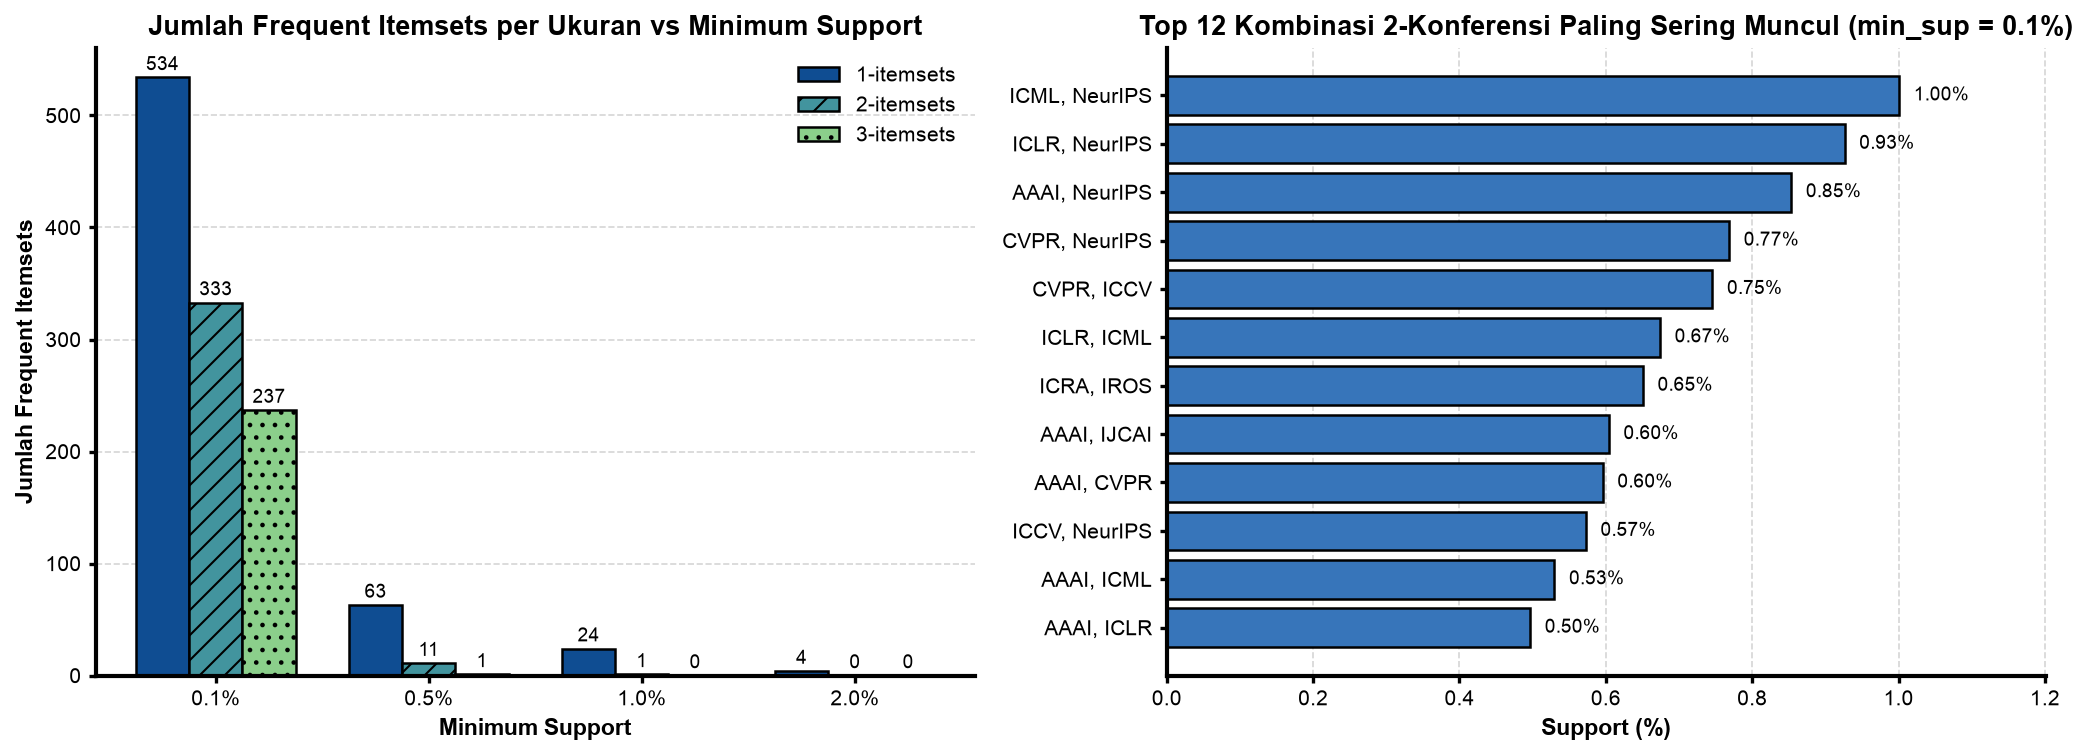

In [4]:
# Visualisasi Task 4: Pengaruh min_support terhadap jumlah frequent itemsets berdasarkan ukuran
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

labels = size_df["min_support_pct"].tolist()
x = np.arange(len(labels))
w = 0.25

axes[0].bar(x - w, size_df["n_1_itemsets"], w, label="1-itemsets", color=PALETTE["blue_main"], edgecolor="black", linewidth=1.2)
axes[0].bar(x, size_df["n_2_itemsets"], w, label="2-itemsets", color=PALETTE["teal"], edgecolor="black", linewidth=1.2, hatch="//")
axes[0].bar(x + w, size_df["n_3_itemsets"], w, label="3-itemsets", color=PALETTE["green_3"], edgecolor="black", linewidth=1.2, hatch="..")
for i, row in size_df.iterrows():
    axes[0].text(i - w, row["n_1_itemsets"] + 3, str(row["n_1_itemsets"]), ha="center", va="bottom", fontsize=9)
    axes[0].text(i, row["n_2_itemsets"] + 3, str(row["n_2_itemsets"]), ha="center", va="bottom", fontsize=9)
    axes[0].text(i + w, row["n_3_itemsets"] + 3, str(row["n_3_itemsets"]), ha="center", va="bottom", fontsize=9)
axes[0].set_title("Jumlah Frequent Itemsets per Ukuran vs Minimum Support")
axes[0].set_xlabel("Minimum Support")
axes[0].set_ylabel("Jumlah Frequent Itemsets")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].legend(loc="upper right")
clean_axes(axes[0], grid_axis="y")

# Panel B: Top 12 Frequent 2-itemsets (min_support = 0.1%)
top_pairs = is_01[is_01["length"] == 2].head(12).iloc[::-1]
bars = axes[1].barh(top_pairs["itemset"], top_pairs["support_pct"], color=PALETTE["blue_secondary"], edgecolor="black", linewidth=1.2)
for bar in bars:
    val = bar.get_width()
    axes[1].text(val + 0.02, bar.get_y() + bar.get_height()/2, f"{val:.2f}%", va="center", fontsize=9)
axes[1].set_title("Top 12 Kombinasi 2-Konferensi Paling Sering Muncul (min_sup = 0.1%)")
axes[1].set_xlabel("Support (%)")
axes[1].set_xlim(0, top_pairs["support_pct"].max() * 1.2)
clean_axes(axes[1], grid_axis="x")

save_figure(fig, "../outputs/figures/04_fpm_itemsets_analysis")
plt.show()


### Interpretasi Hasil Frequent Pattern Mining (Task 4)
1. **Pengaruh Minimum Support**: Kenaikan `min_support` menurunkan jumlah frequent itemsets secara tajam dan non-linear (prinsip *anti-monotone* / *downward closure*). Pada `2%` hanya segelintir konferensi mega-populer yang lolos sebagai 1-itemset dan hampir tidak ada/tidak ada kombinasi multi-itemset; sebaliknya pada `0.1%` terbentuk ratusan frequent 1-itemsets, 2-itemsets, dan 3-itemsets yang merepresentasikan ekosistem sub-bidang Computer Science.
2. **Klaster Komunitas Riset**: Kombinasi 2-itemsets dan 3-itemsets teratas secara jelas membentuk klaster domain riset yang kohesif:
   - **Machine Learning / AI**: `{NeurIPS, ICML}`, `{NeurIPS, ICLR}`, `{ICML, ICLR}`, `{NeurIPS, AAAI}`, `{NeurIPS, ICML, ICLR}`.
   - **Computer Vision**: `{CVPR, ICCV}`, `{CVPR, ECCV}`, `{CVPR, ICCV, ECCV}`.
   - **NLP**: `{ACL, EMNLP}`, `{ACL, EMNLP, NAACL}`.
   - **Robotics**: `{ICRA, IROS}`.
   - **Communications & Signal Processing**: `{ICC, GLOBECOM}`, `{ICASSP, INTERSPEECH}`.


## 2. Task 5 — Association Rule Mining (`min_confidence = 50%`)


In [5]:
print(f"Total association rules (min_support=0.1%, min_conf=50%): {len(rules_01):,}")
print("\n=== Top 10 Association Rules Berdasarkan Lift Tertinggi ===")
display(top10_rules[["rule", "support_pct", "confidence_pct", "lift", "tx_count"]])

print("\n=== Top 10 Association Rules Berdasarkan Support Tertinggi ===")
display(rules_01.sort_values("support", ascending=False).head(10)[["rule", "support_pct", "confidence_pct", "lift", "tx_count"]])


Total association rules (min_support=0.1%, min_conf=50%): 730

=== Top 10 Association Rules Berdasarkan Lift Tertinggi ===


,rule,support_pct,confidence_pct,lift,tx_count
0,"ACM Multimedia, CVPR, NeurIPS -> AAAI, ICCV",0.1276,55.33,122.6761,2325
1,"CVPR, IJCAI, NeurIPS -> AAAI, ICCV",0.1072,55.11,122.1804,1953
2,"ICCV, ICML, NeurIPS -> CVPR, ICLR",0.1321,56.44,122.1401,2407
3,"ICCV, IJCAI, NeurIPS -> AAAI, CVPR",0.1072,67.72,113.6638,1953
4,"ACM Multimedia, ICCV, NeurIPS -> AAAI, CVPR",0.1276,66.56,111.7222,2325
5,"ICLR, IJCAI, NeurIPS -> AAAI, ICML",0.1215,56.77,107.1805,2214
6,"ICML, IJCAI, NeurIPS -> AAAI, ICLR",0.1215,52.24,105.2042,2214
7,"AAAI, CVPR, ICLR -> ICCV, NeurIPS",0.1376,58.72,102.5386,2508
8,"AAAI, CVPR, ICML -> ICCV, NeurIPS",0.1243,57.02,99.5745,2265
9,"ICCV, IJCAI -> AAAI, CVPR",0.1309,59.09,99.1789,2386



=== Top 10 Association Rules Berdasarkan Support Tertinggi ===


,rule,support_pct,confidence_pct,lift,tx_count
703,ICML -> NeurIPS,1.0008,58.09,18.8810,18239
697,ICLR -> NeurIPS,0.9263,58.72,19.0846,16882
479,ICCV -> CVPR,0.7456,56.35,29.3655,13588
380,"ICML, NeurIPS -> ICLR",0.5445,54.41,34.4904,9924
553,"ICLR, ICML -> NeurIPS",0.5445,80.78,26.2556,9924
392,"ICLR, NeurIPS -> ICML",0.5445,58.78,34.1224,9924
328,"ICCV, NeurIPS -> CVPR",0.4281,74.75,38.9583,7802
706,"CVPR, ICCV -> NeurIPS",0.4281,57.42,18.6621,7802
283,"CVPR, NeurIPS -> ICCV",0.4281,55.70,42.0988,7802
584,"AAAI, ICML -> NeurIPS",0.4091,77.24,25.1047,7456


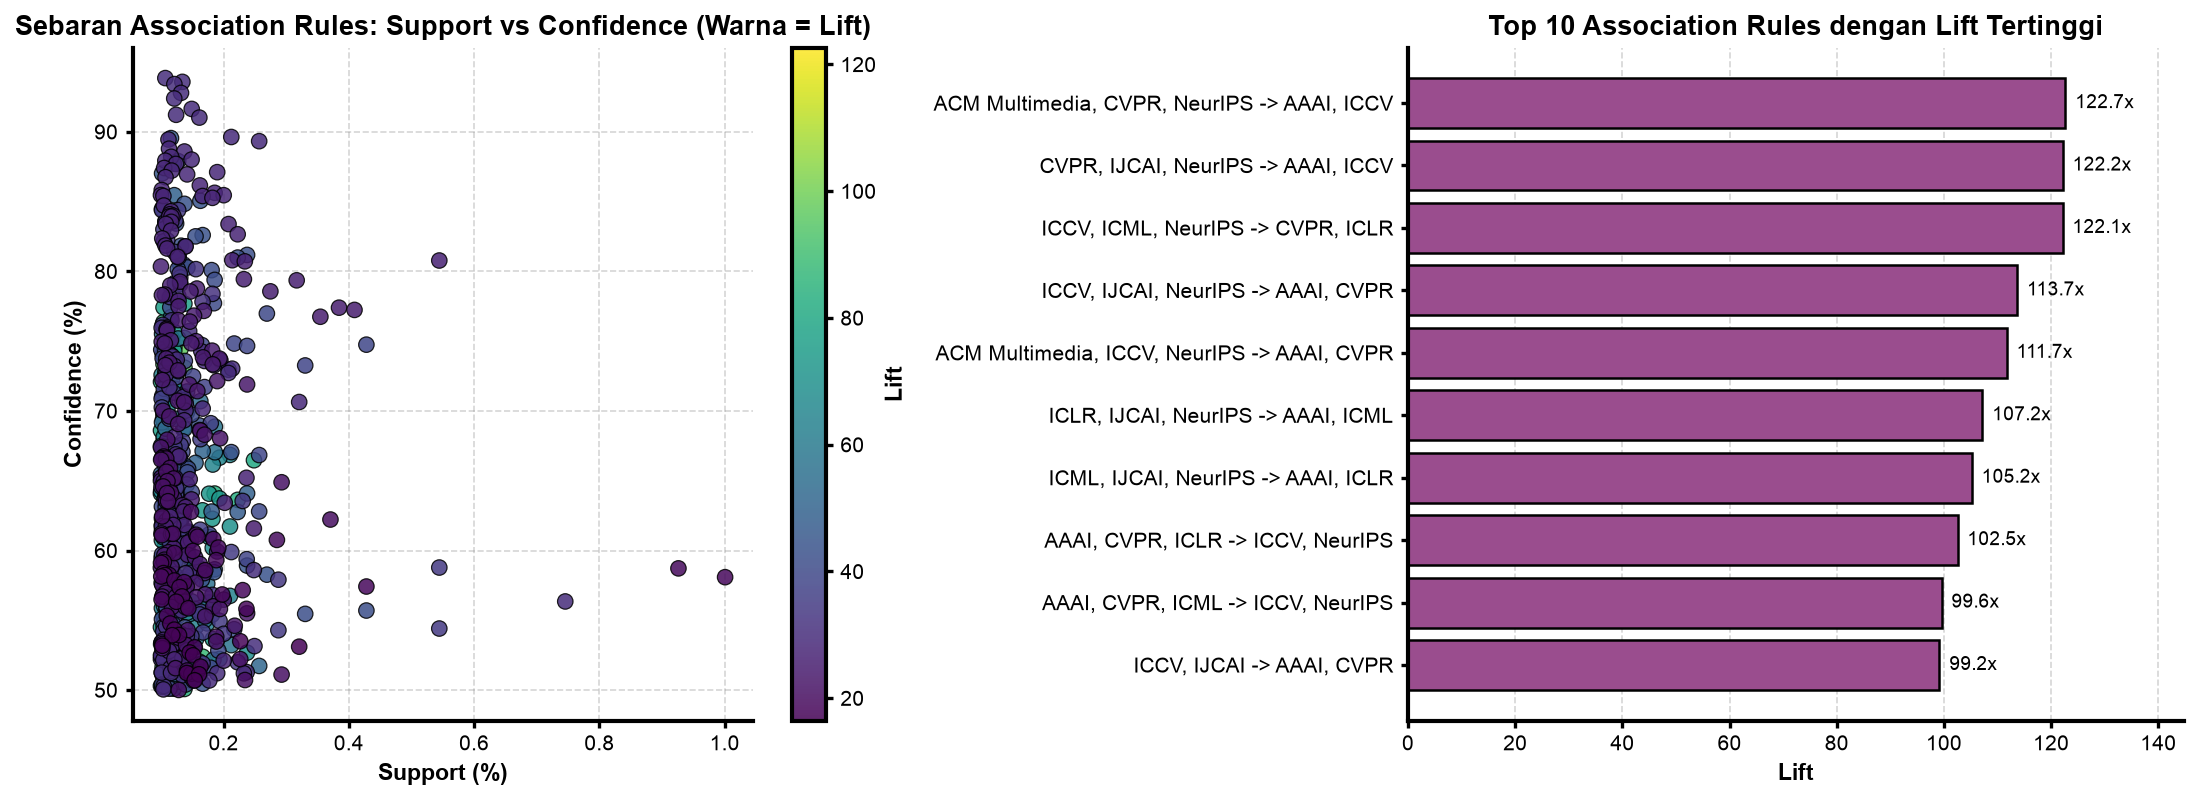

In [6]:
# Visualisasi Task 5: Support vs Confidence (colored by Lift) & Top 10 Rules by Lift
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5))

if not rules_01.empty:
    sc = axes[0].scatter(
        rules_01["support_pct"],
        rules_01["confidence_pct"],
        c=rules_01["lift"],
        cmap="viridis",
        s=55,
        alpha=0.85,
        edgecolors="black",
        linewidths=0.6,
    )
    cbar = fig.colorbar(sc, ax=axes[0])
    cbar.set_label("Lift", fontweight="bold")
    axes[0].set_title("Sebaran Association Rules: Support vs Confidence (Warna = Lift)")
    axes[0].set_xlabel("Support (%)")
    axes[0].set_ylabel("Confidence (%)")
    clean_axes(axes[0], grid_axis="both")

    t10 = top10_rules.iloc[::-1]
    bars = axes[1].barh(t10["rule"], t10["lift"], color=PALETTE["violet"], edgecolor="black", linewidth=1.2)
    for bar in bars:
        val = bar.get_width()
        axes[1].text(val + max(t10["lift"]) * 0.015, bar.get_y() + bar.get_height()/2, f"{val:.1f}x", va="center", fontsize=9)
    axes[1].set_title("Top 10 Association Rules dengan Lift Tertinggi")
    axes[1].set_xlabel("Lift")
    axes[1].set_xlim(0, t10["lift"].max() * 1.18)
    clean_axes(axes[1], grid_axis="x")

save_figure(fig, "../outputs/figures/05_association_rules_analysis")
plt.show()


### Analisis & Interpretasi Association Rules (Task 5)
1. **Apakah conference dengan support tinggi selalu menghasilkan lift tinggi?**
   - **Tidak.** Secara matematis, $\text{Lift}(A \rightarrow B) = \frac{P(A \cap B)}{P(A)P(B)} = \frac{\text{Confidence}(A \rightarrow B)}{P(B)}$. Konferensi ber-support sangat tinggi (seperti `NeurIPS`, `AAAI`, `CVPR`) memiliki penyebut $P(B)$ yang besar sehingga lift-nya cenderung lebih moderat dibandingkan pasangan konferensi yang lebih terspesialisasi/niche namun memiliki basis komunitas yang sangat tumpang tindih (seperti pasangan konferensi spesifik bidang tertentu atau sub-track/workshop yang erat).
2. **Perbedaan Interpretasi Support, Confidence, dan Lift**:
   - **Support** $P(A \cup B)$: proporsi seluruh author yang pernah memublikasikan di kedua kelompok konferensi $A$ dan $B$ (mengukur *cakupan/popularitas* pola).
   - **Confidence** $P(B \mid A)$: peluang bersyarat seorang author memublikasikan di $B$ jika diketahui ia pernah memublikasikan di $A$ (mengukur *kekuatan arah implikasi*, namun rentan bias jika $B$ memang sangat populer).
   - **Lift** $\frac{P(B \mid A)}{P(B)}$: rasio peningkatan peluang publikasi di $B$ dibandingkan ekspektasi acak (independen). $\text{Lift} > 1$ menunjukkan asosiasi positif sejati, $\text{Lift} = 1$ independen, dan $\text{Lift} < 1$ asosiasi negatif.
3. **Pola Publikasi Antar-Konferensi**: Rules dengan lift dan confidence tinggi memperlihatkan struktur klaster riset yang kuat (peneliti cenderung aktif secara berulang di ekosistem konferensi yang serumpun, misalnya rangkaian konferensi utama ML, CV, NLP, Robotics, dan Telecommunications).


## 3. Task 6 — Algorithm Performance Comparison (Apriori vs FP-Growth)


,min_support,min_support_pct,candidate_items_ge_minsup,apriori_itemsets,fpgrowth_itemsets,itemsets_identical,apriori_rules,fpgrowth_rules,apriori_time_s,fpgrowth_time_s,speedup_fpgrowth_vs_apriori,apriori_peak_mb,fpgrowth_peak_mb
0,0.001,0.1%,534,1197,1197,True,730,730,21.2570,77.9314,0.27,1893.34,951.97
1,0.005,0.5%,63,75,75,True,6,6,1.0242,53.5919,0.02,240.32,125.58
2,0.010,1.0%,24,25,25,True,1,1,0.3532,57.7603,0.01,100.00,55.44
3,0.020,2.0%,4,4,4,True,0,0,0.0513,50.6141,0.00,30.80,18.32


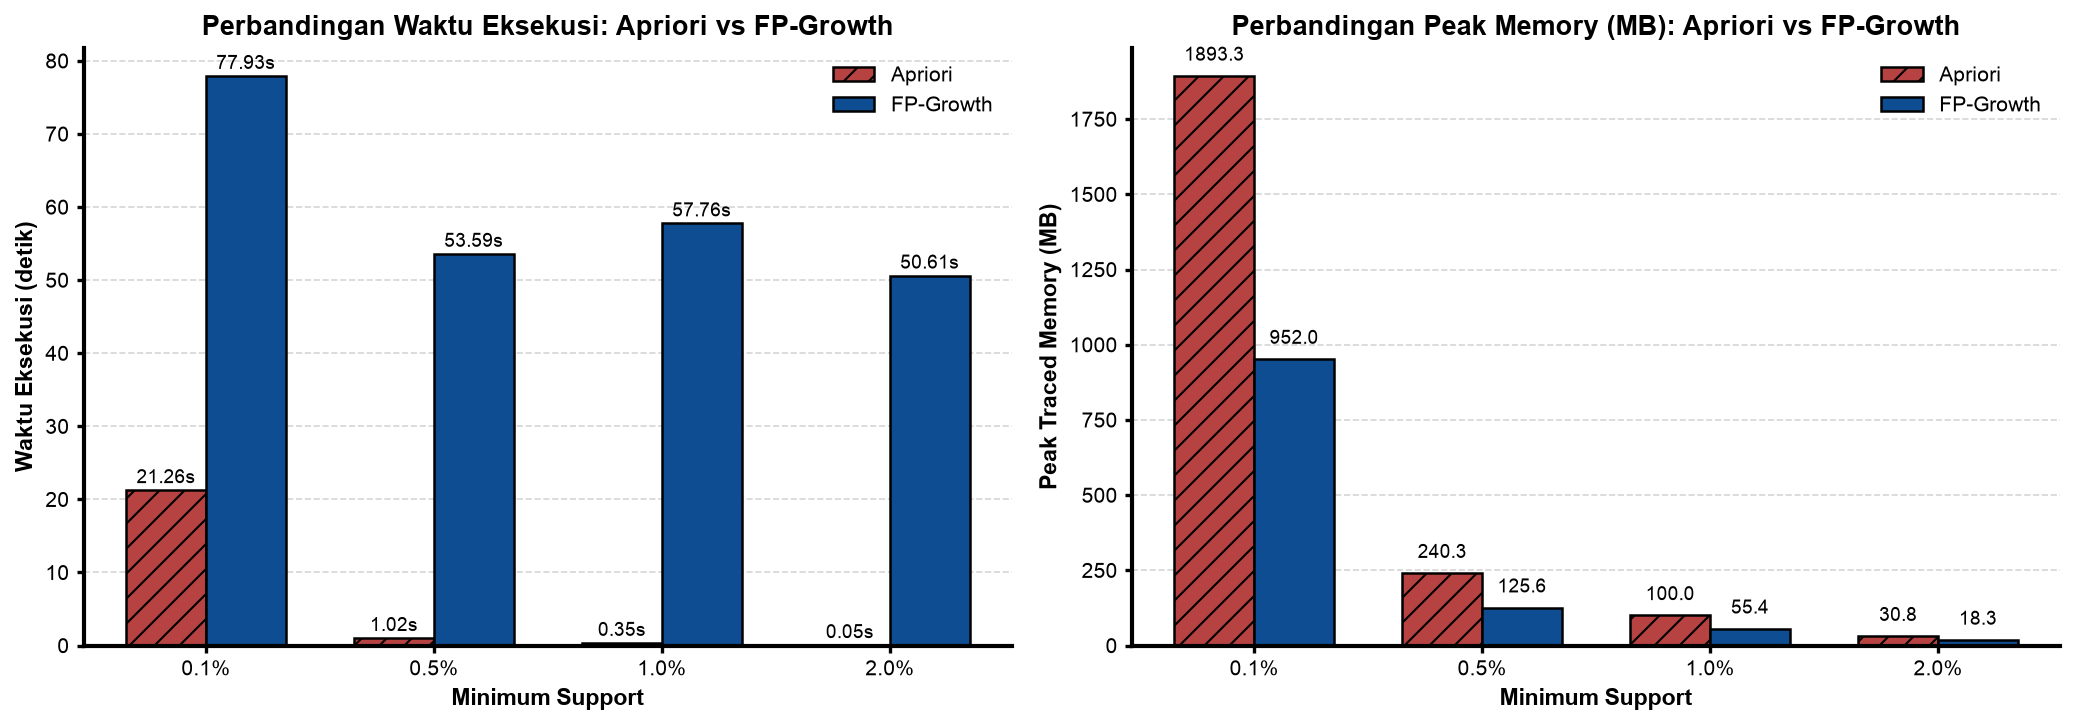

In [7]:
display(comp_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.0))
labels = comp_df["min_support_pct"].tolist()
x = np.arange(len(labels))
w = 0.35

# Panel A: Runtime comparison
axes[0].bar(x - w/2, comp_df["apriori_time_s"], w, label="Apriori", color=PALETTE["red_strong"], edgecolor="black", linewidth=1.2, hatch="//")
axes[0].bar(x + w/2, comp_df["fpgrowth_time_s"], w, label="FP-Growth", color=PALETTE["blue_main"], edgecolor="black", linewidth=1.2)
for i, row in comp_df.iterrows():
    axes[0].text(i - w/2, row["apriori_time_s"] + max(comp_df["apriori_time_s"]) * 0.02, f"{row['apriori_time_s']:.2f}s", ha="center", va="bottom", fontsize=9)
    axes[0].text(i + w/2, row["fpgrowth_time_s"] + max(comp_df["apriori_time_s"]) * 0.02, f"{row['fpgrowth_time_s']:.2f}s", ha="center", va="bottom", fontsize=9)
axes[0].set_title("Perbandingan Waktu Eksekusi: Apriori vs FP-Growth")
axes[0].set_xlabel("Minimum Support")
axes[0].set_ylabel("Waktu Eksekusi (detik)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].legend(loc="upper right")
clean_axes(axes[0], grid_axis="y")

# Panel B: Peak Memory comparison
axes[1].bar(x - w/2, comp_df["apriori_peak_mb"], w, label="Apriori", color=PALETTE["red_strong"], edgecolor="black", linewidth=1.2, hatch="//")
axes[1].bar(x + w/2, comp_df["fpgrowth_peak_mb"], w, label="FP-Growth", color=PALETTE["blue_main"], edgecolor="black", linewidth=1.2)
for i, row in comp_df.iterrows():
    axes[1].text(i - w/2, row["apriori_peak_mb"] + max(comp_df["apriori_peak_mb"]) * 0.02, f"{row['apriori_peak_mb']:.1f}", ha="center", va="bottom", fontsize=9)
    axes[1].text(i + w/2, row["fpgrowth_peak_mb"] + max(comp_df["apriori_peak_mb"]) * 0.02, f"{row['fpgrowth_peak_mb']:.1f}", ha="center", va="bottom", fontsize=9)
axes[1].set_title("Perbandingan Peak Memory (MB): Apriori vs FP-Growth")
axes[1].set_xlabel("Minimum Support")
axes[1].set_ylabel("Peak Traced Memory (MB)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].legend(loc="upper right")
clean_axes(axes[1], grid_axis="y")

save_figure(fig, "../outputs/figures/06_algorithm_performance_comparison")
plt.show()


### Jawaban Pertanyaan Evaluasi (Task 6)
1. **Bagaimana perubahan `min_support` memengaruhi performa kedua algoritma?**
   - Penurunan `min_support` dari `2%` ke `0.1%` meningkatkan jumlah kandidat item dari `4` menjadi `534`, jumlah frequent itemsets dari `4` menjadi `1,197`, dan jumlah association rules (`conf >= 50%`) dari `0` menjadi `730`.
   - Waktu eksekusi **Apriori** meningkat tajam dari `0.05 detik` (`2%`) menjadi `21.26 detik` (`0.1%`) dengan *peak memory* melonjak dari `30.8 MB` ke `1,893.3 MB` akibat pembangkitan kandidat berulang. Sementara itu, **FP-Growth** mengalami peningkatan waktu yang jauh lebih landai (`50.61 detik` → `77.93 detik`) karena memiliki *fixed overhead* konstruksi FP-Tree di Python atas `1.82 juta` baris, namun konsumsi memorinya konsisten **~2x lebih hemat** (`952.0 MB` pada `0.1%`).
2. **Apakah kedua algoritma menghasilkan frequent itemsets yang sama?**
   - **Ya, 100% identik** pada seluruh nilai `min_support` (`0.1%`, `0.5%`, `1%`, `2%`) — baik himpunan itemsets, nilai support (selisih `< 1e-12`), maupun jumlah association rules yang dibangkitkan (`itemsets_identical = True` untuk semua pengujian).
3. **Algoritma mana yang lebih sesuai untuk dataset DBLP yang digunakan?**
   - Secara **efisiensi memori dan skalabilitas untuk `min_support` sangat rendah (`<= 0.1%`)**, **FP-Growth** lebih unggul karena memangkas *peak memory* hingga **~50%** (`952 MB` vs `1,893 MB`) dan tidak mengalami ledakan pembangkitan kandidat (*candidate generation*).
   - Secara **kecepatan praktis di pustaka Python `mlxtend` pada rentang `min_support` `0.1%–2%`**, **Apriori (`low_memory=True` pada matriks sparse)** justru lebih cepat (`0.05–21.26 detik` vs `50.61–77.93 detik`) karena memanfaatkan operasi vektorisasi NumPy/SciPy pada kolom sparse, sedangkan `mlxtend.fpgrowth` membangun FP-Tree secara iteratif di pure Python. Oleh karena itu, untuk eksperimen cepat pada `min_support >= 0.1%` di RAM cukup besar, Apriori sparse sangat efektif; namun untuk keterbatasan RAM atau eksplorasi pola yang lebih dalam (`min_support < 0.1%`), **FP-Growth** merupakan pilihan yang lebih tepat dan skalabel.
